# Part I — The data
**Question of the project:** *before a Grand Prix starts, can we predict who will finish ahead of whom better than the starting grid does, and will our model be right on the real races still to come?*

**This notebook:** where the data comes from, what one row is, and the one rule that keeps the project honest.

| | |
|---|---|
| **Source** | Official Formula 1 race results, as stored in the open F1DB database (github.com/f1db/f1db, CC BY 4.0). One single source for every number. |
| **Snapshot** | `data/raw/f1db-csv.zip`, downloaded 21 Oct 2026 (after the Singapore GP), SHA-256 checksum in `data/raw/` |
| **Period** | 2014–2026: the turbo-hybrid era, with the same points system throughout (top 10 score) |
| **One row** | one driver who started one Grand Prix |
| **Golden rule** | a feature for race *r* only uses races **before** *r* (grid, qualifying and practice are allowed: they are known on Saturday, before the race) |

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1duel.data import build, TEAM_STATS
from f1duel.plots import style, title, save, BLUE, ORANGE, AQUA, GREY, INK, INK2, MUTED, TIER_COLORS
style(); pd.set_option('display.width', 140); pd.set_option('display.max_columns', 20)
d = build()
print(f"{len(d):,} driver starts | {d.raceId.nunique()} races | {d.driverId.nunique()} drivers | {d.year.min()}–{d.year.max()}")
d[['year','gp_name','driver_name','team_name','grid','quali_gap','practice_gap','finish_pos','top10']].tail(5)

5,435 driver starts | 269 races | 63 drivers | 2014–2026


,year,gp_name,driver_name,team_name,grid,quali_gap,practice_gap,finish_pos,top10
5430,2026,Singapore,Valtteri Bottas,Cadillac,18.0,5.000000,3.626157,19.0,0
5431,2026,Singapore,George Russell,Mercedes,19.0,0.409311,0.000000,9.0,1
5432,2026,Singapore,Isack Hadjar,Red Bull,22.0,5.000000,1.570323,10.0,1
5433,2026,Singapore,Fernando Alonso,Aston Martin,22.0,3.119083,2.406962,16.0,0
5434,2026,Singapore,Lance Stroll,Aston Martin,22.0,3.910346,3.244684,NaN,0


### What we predict, and what we use

| Target (what happened) | Meaning |
|---|---|
| `finish_pos` | finishing position (empty = did not finish) |
| `top10` | 1 if the driver finished in the top 10 = scored points |
| `win` | 1 if the driver won |

| Feature | Known when | Meaning |
|---|---|---|
| `grid` | Saturday | starting position after penalties |
| `quali_gap` | Saturday | gap to pole position in qualifying (%) |
| `practice_gap` | Friday/Saturday | gap to the fastest practice lap (%) |
| 7 team statistics | Monday | team points, top-10 rate, podium rate, average finish, average grid, qualifying gap (last 5 races) and mechanical failures (last 10) |
| `drv_avg_finish`, `drv_top10` | Monday | driver's average finish and top-10 rate over his last 5 starts |

In [2]:
d[TEAM_STATS + ['drv_avg_finish','drv_top10']].describe().round(2).T[['mean','std','min','max']]

,mean,std,min,max
team_points,10.00,11.02,0.0,44.4
team_top10,0.50,0.32,0.0,1.0
team_podium,0.15,0.24,0.0,1.0
team_avg_finish,10.79,4.11,1.5,20.0
team_avg_grid,10.70,4.61,1.5,22.0
team_quali_gap,1.66,1.14,0.0,5.0
team_mech_dnf,0.08,0.09,0.0,1.0
drv_avg_finish,10.77,4.43,1.0,20.0
drv_top10,0.50,0.35,0.0,1.0


### The starting point: the grid already says a lot

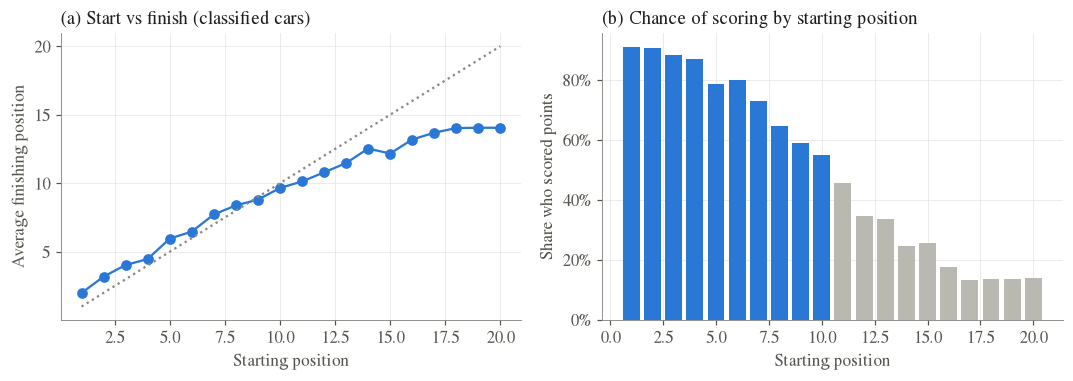

Pole sitter scores 91% of the time; 10th 55%; 11th 45%; 20th 14%


In [3]:
c = d[d.finish_pos.notna()]
by_grid = c.groupby(c.grid.clip(upper=20)).finish_pos.mean()
top10_rate = d.groupby(d.grid.clip(upper=20)).top10.mean()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(by_grid.index, by_grid.values, 'o-', color=BLUE); ax[0].plot([1, 20], [1, 20], ls=':', color=MUTED)
ax[0].set_xlabel('Starting position'); ax[0].set_ylabel('Average finishing position'); title(ax[0], '(a) Start vs finish (classified cars)')
ax[1].bar(top10_rate.index, top10_rate.values, color=[BLUE if g <= 10 else GREY for g in top10_rate.index])
ax[1].set_xlabel('Starting position'); ax[1].set_ylabel('Share who scored points'); ax[1].yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
title(ax[1], '(b) Chance of scoring by starting position')
fig.tight_layout(); save(fig, '01_grid'); plt.show()
print(f"Pole sitter scores {top10_rate[1]:.0%} of the time; 10th {top10_rate[10]:.0%}; 11th {top10_rate[11]:.0%}; 20th {top10_rate[20]:.0%}")

**Reading:** the grid is a strong guide, but not a perfect one. Starting 10th or 11th is close to a coin flip, and even the pole sitter misses the points sometimes. This is the **baseline every model must beat** (the professor's request): *"the 10 drivers who start in the top 10 are the 10 who score"*.

In [4]:
races = d.groupby('raceId')
hits = races.apply(lambda g: int(g.top10[g.grid.rank(method='first') <= 10].sum()), include_groups=False)
print(f"Grid rule: on average {hits.mean():.2f} of the 10 drivers starting in the top 10 score points (all {len(hits)} races, 2014-2026).")
print("(The test seasons used later, 2020-2025, give 7.71: that is the number the models are compared with.)")

Grid rule: on average 7.64 of the 10 drivers starting in the top 10 score points (all 269 races, 2014-2026).


(The test seasons used later, 2020-2025, give 7.71: that is the number the models are compared with.)
